# 05 · Torneo de modelos · Descartar con evidencia, no coronar

> **BORRADOR para revisión del grupo.** Todo se mide en el **entrenamiento**, con los **mismos 5 pliegues** de las etapas 3 y 4 y las variables decididas en `reports/04_features.md`. La prueba cerrada **no se abre**.
> Los estados de decisión son **[DECIDIDO]** (resuelto con evidencia del proyecto), **[ADOPTADO]** (propuesta vigente por defecto hasta que el grupo diga lo contrario) o **[PENDIENTE: dato externo]** (no se puede resolver con estos datos); registro completo en `reports/decisiones_del_grupo.md`. El código vive en `src/proyecto/models/` (`train.py`, `baselines.py`, `metrics.py`) con pruebas en `tests/`; este notebook solo lo orquesta.

**El torneo descarta, no corona.** Elige **uno o dos finalistas** para optimizar en la etapa 6. La optimización puede cambiar el orden y solo la prueba final (etapa 7) dice qué tan bueno es el modelo que se elija.

## Resumen para quien decide

| | Lo que se midió | Qué significa para el negocio |
|---|---|---|
| **1** | **LightGBM** tiene el menor costo: **0,3245** por cliente, frente a **0,398** de la regla "llamar si hubo daño" y **0,613** de no llamar a nadie | Frente a la regla simple, el modelo ahorra **≈ 7.400 unidades de llamada por cada 100.000 clientes** (18,5 %) |
| **2** | **LightGBM y XGBoost empatan en la práctica**: 0,0014 de diferencia, gana en 4 de 5 pliegues, **+1,0 veces el ruido** | Se elige LightGBM por **ser casi el doble de rápido** de ajustar; XGBoost queda como respaldo |
| **3** | La **regresión logística** (la más fácil de explicar) cuesta **0,3278**: **≈ 340 unidades más** por 100.000 clientes que LightGBM, pero **supera al bosque, al árbol y a las líneas base** | Es el **segundo finalista**: lo que se paga por poder explicar cada predicción con una fórmula |
| **4** | El **bosque aleatorio** ordena tan bien como la regresión (ROC-AUC 0,854 los dos) pero **cuesta más** (0,3355) y tarda **9 veces más** en ajustarse | Un caso claro de que **ordenar bien no es decidir bien**: sus probabilidades no están calibradas |
| **5** | Con la decisión por umbral, los modelos **casi no llaman** a los de 20-25 años ni a los de 66 o más: recall de **36 % y 40 %** | Cuidado de equidad por edad para la etapa 7 y para la política comercial |

## 0. Cargar el entrenamiento y los pliegues comunes

In [1]:
import sys
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve()
ROOT = ROOT if (ROOT / "src").exists() else ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone

from proyecto.data import split as sp
from proyecto.data.loading import load_train
from proyecto.models.metrics import (TOP_SHARE, audit_by_group, calibration_table, cost_per_client, cost_sensitivity, decision_threshold,
                                     paired_comparison, technical_metrics)
from proyecto.models.train import TOURNAMENT_FEATURES, TOURNAMENT_FEATURES_LINEAR, run_tournament, tournament_candidates

TARGET = "Response"
BLUE, ORANGE, GRAY, LIGHT, INK = "#2F6FB5", "#D9822B", "#8A8A8A", "#C9C9C4", "#222222"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#cccccc",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#eeeeee",
                     "axes.axisbelow": True, "font.size": 10, "axes.titleweight": "bold", "axes.titlesize": 11,
                     "axes.titlelocation": "left", "figure.dpi": 110})

train = load_train(ROOT)                    # solo entrenamiento: la prueba cerrada no se carga
X, y = train.drop(columns=[TARGET]), train[TARGET]
folds = sp.stratified_folds(train, n_splits=5)      # los MISMOS pliegues de las etapas 3 y 4

for tr_idx, va_idx in folds:
    assert set(tr_idx).isdisjoint(set(va_idx))
assert sorted(np.concatenate([va for _, va in folds])) == list(range(len(train)))
print(f"Entrenamiento: {len(train):,} clientes; tasa de aceptación {y.mean():.3%}; {len(folds)} pliegues estratificados.")
print(f"Umbral de decisión (R = 5): llamar si la probabilidad supera {decision_threshold():.1%}. Capacidad de referencia: el {TOP_SHARE:.0%} mejor puntuado.")

Entrenamiento: 304,887 clientes; tasa de aceptación 12.256%; 5 pliegues estratificados.
Umbral de decisión (R = 5): llamar si la probabilidad supera 16.7%. Capacidad de referencia: el 20% mejor puntuado.


## 1. Las reglas del torneo y los criterios de elección

**Reglas (guía, sección 2.1):**
1. **Mismos datos y mismos pliegues para todos.** Los 5 pliegues estratificados de la etapa 3.
2. **Líneas base** que cualquier modelo serio debe vencer: "no llamar a nadie" y, la más exigente, la regla de negocio "**llamar si hubo daño**".
3. **Se guarda cada pliegue**, no solo el promedio, para comparar de a pares.
4. **Mismas variables para todos:** las de la etapa 4 (sin `Vintage`, `Driving_License` ni `Gender`). La **única diferencia** es que la regresión recibe la edad como curva (la mejora de +6 veces el ruido de la etapa 4), porque un modelo lineal la necesita y los árboles no.

**Cómo se elige (escrito antes de ver resultados) [ADOPTADO · D05]:**

| Orden | Criterio | Regla propuesta | Por qué importa al negocio |
|---|---|---|---|
| 1 | **Consistencia** | Gana en 4 de 5 pliegues y la diferencia supera 1 vez el ruido; si no, es un **empate práctico** | Una ventaja que cambia de signo según el pliegue no es una ventaja |
| 2 | **Métrica de negocio** | Menor **costo por cliente** (R = 5, umbral 16,7 %) | Es lo que el negocio paga |
| 3 | **Ranking sin depender del umbral** | PR-AUC, ROC-AUC y recall en el 20 % mejor puntuado | Si la capacidad de llamadas es fija, importa quién queda arriba, no el umbral |
| 4 | **Tiempo y simplicidad** | Ante un empate, gana el más rápido y simple | Reentrenar, desplegar y mantener cuesta tiempo |
| 5 | **Explicabilidad** | Se pesa **solo si la exige el negocio o el regulador** **[PENDIENTE: dato externo · P03]**; si cuesta algo, se traduce a dinero | "¿Por qué se le llamó a este cliente?" |

**Las dos familias de métricas** (siempre las dos): **de negocio** (costo por cliente, costo si se llama al 20 % mejor puntuado) y **técnicas** (ROC-AUC, PR-AUC, exactitud balanceada, precisión y recall por clase, F1 macro, log loss, Brier).
> **No se usa la exactitud simple:** con 12,26 % de compradores, "no llamar a nadie" ya acierta el 87,7 %.

## 2. Los candidatos

Todos con **parámetros fijos y razonables, sin ajustar** (ajustar es la etapa 6). Si un modelo gana con parámetros de partida, la optimización solo puede mejorarlo; si pierde, rara vez cambia de lugar.

| Modelo | Qué es | Por qué está en el torneo | Parámetros fijos | ¿Se puede explicar? |
|---|---|---|---|---|
| **Línea base: no llamar a nadie** | Predice siempre la proporción de compradores (12,26 %) | El piso: lo que cuesta no hacer nada | — | Trivial |
| **Línea base: llamar si hubo daño** | Aprende la tasa de aceptación con y sin daño y llama a todo cliente con daño | **El rival que importa:** lo que haría el equipo comercial sin modelo | — | Trivial |
| **Regresión logística** | Una fórmula: suma de pesos por variable, con la edad como curva | El modelo simple e **interpretable** | `C = 1`, variables escaladas | **Sí**, cada variable tiene un peso |
| **Árbol de decisión** | Una cascada de preguntas de sí o no | Interpretable de otra forma: **reglas** que se pueden leer | profundidad 5, mínimo 200 clientes por hoja | Sí, reglas legibles |
| **Bosque aleatorio** | 150 árboles que votan | El clásico robusto | profundidad 16, mínimo 50 por hoja | Poco |
| **LightGBM** | Árboles que se corrigen uno a otro (*boosting*) | Suele ser el mejor en datos tabulares y rápido | 200 árboles, tasa 0,08, 31 hojas | Poco (se puede aproximar con importancias) |
| **XGBoost** | Otro *boosting*, con la misma idea | Segunda opinión: ¿el resultado depende de la librería? | 200 árboles, tasa 0,08, profundidad 6 | Poco |

In [2]:
candidates = tournament_candidates()
print(f"{len(candidates)} candidatos: {sum(n.startswith('línea base') for n in candidates)} líneas base y {sum(not n.startswith('línea base') for n in candidates)} modelos.")

# Qué variables recibe cada familia
from proyecto.features.engineering import build_preprocessor
names_trees = list(build_preprocessor(TOURNAMENT_FEATURES).fit(X.iloc[folds[0][0]], y.iloc[folds[0][0]]).get_feature_names_out())
names_linear = list(build_preprocessor(TOURNAMENT_FEATURES_LINEAR).fit(X.iloc[folds[0][0]], y.iloc[folds[0][0]]).get_feature_names_out())
print(f"Modelos de árboles: {len(names_trees)} columnas tras el preprocesamiento. Regresión: {len(names_linear)} (la edad pasa de 1 columna a una curva de varias).")
print("Variables retiradas en la etapa 4 y ausentes aquí:", [c for c in ("Vintage", "Driving_License", "Gender") if not any(n.startswith(c) for n in names_trees)])
print("Datos que pide la app (7):", ["Previously_Insured", "Vehicle_Damage", "Vehicle_Age", "Age", "Region_Code", "Policy_Sales_Channel", "Annual_Premium"])

7 candidatos: 2 líneas base y 5 modelos.


Modelos de árboles: 108 columnas tras el preprocesamiento. Regresión: 114 (la edad pasa de 1 columna a una curva de varias).
Variables retiradas en la etapa 4 y ausentes aquí: ['Vintage', 'Driving_License', 'Gender']
Datos que pide la app (7): ['Previously_Insured', 'Vehicle_Damage', 'Vehicle_Age', 'Age', 'Region_Code', 'Policy_Sales_Channel', 'Annual_Premium']


## 3. Correr el torneo

En cada pliegue se ajusta el modelo con 4 partes, se predice la quinta y se calculan **todas las métricas**. Se guardan **las probabilidades fuera de muestra** de cada cliente (cada cliente se predice una vez, con un modelo que no lo vio). Son la base de las secciones de calibración, sensibilidad a R y revisión por grupos.
Son unos 3 minutos: el bosque aleatorio es el más lento.

In [3]:
t_start = time.time()
per_fold, oof = run_tournament(candidates, X, y, folds)      # la lógica vive en src/proyecto/models/train.py
print(f"{len(per_fold)} candidatos x {len(folds)} pliegues en {(time.time() - t_start) / 60:.1f} minutos.")

7 candidatos x 5 pliegues en 3.1 minutos.


## 4. Resultado de negocio: ¿cuánto cuesta decidir con cada modelo?

**Cómo leer la tabla:** `costo` es el promedio por cliente en **unidades de llamada** (1 = una llamada que no vende; R = 5 si no se llama a un comprador). `± ruido` es la desviación entre los 5 pliegues. `unidades por campaña` lo convierte a un volumen concreto.
`costo si solo se llama al 20 %` responde "¿y si el equipo solo puede llamar al 20 % mejor puntuado?": **no depende de que las probabilidades estén calibradas**.

,costo,± ruido,costo si solo se llama al 20 %,unidades por campaña,segundos de ajuste
LightGBM,0.3245,0.0036,0.3849,"32,446",2.6
XGBoost,0.3259,0.0038,0.3845,"32,586",5.2
regresión logística,0.3278,0.0027,0.3906,"32,782",1.8
bosque aleatorio,0.3355,0.0033,0.3903,"33,548",24.4
árbol de decisión,0.3377,0.0014,0.4304,"33,767",0.8
línea base: llamar si hubo daño,0.3980,0.0023,0.5275,"39,803",0.0
línea base: no llamar a nadie,0.6128,0.0000,0.6653,"61,282",0.0


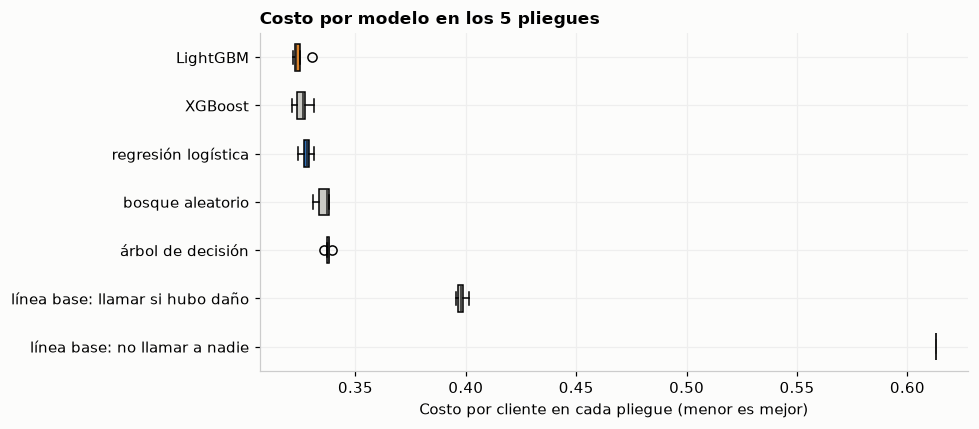

In [4]:
CLIENTES_POR_CAMPANA = 100_000       # [DECIDIDO · D09] escala de reporte (por 100.000 clientes), no un pronóstico

summary = pd.DataFrame({
    name: {"costo": f["cost"].mean(), "± ruido": f["cost"].std(ddof=1), "costo si solo se llama al 20 %": f["cost_top"].mean(),
           "unidades por campaña": f["cost"].mean() * CLIENTES_POR_CAMPANA, "segundos de ajuste": f["fit_seconds"].mean()}
    for name, f in per_fold.items()
}).T.sort_values("costo")
display(summary.style.format({"costo": "{:.4f}", "± ruido": "{:.4f}", "costo si solo se llama al 20 %": "{:.4f}",
                              "unidades por campaña": "{:,.0f}", "segundos de ajuste": "{:.1f}"}))

order = list(summary.index)
fig, ax = plt.subplots(figsize=(9, 4))
data = [per_fold[n]["cost"] for n in order]
bp = ax.boxplot(data, vert=False, tick_labels=order, widths=0.55, patch_artist=True, medianprops={"color": INK})
for patch, name in zip(bp["boxes"], order):
    patch.set_facecolor(ORANGE if name == "LightGBM" else BLUE if name == "regresión logística" else LIGHT)
ax.invert_yaxis()
ax.set_xlabel("Costo por cliente en cada pliegue (menor es mejor)")
ax.set_title("Costo por modelo en los 5 pliegues")
plt.tight_layout()
plt.show()

**Lectura:**
- **LightGBM lidera: 0,3245 ± 0,0036**, seguido de XGBoost (0,3259), regresión logística (0,3278), bosque aleatorio (0,3355) y árbol de decisión (0,3377).
- **Todos los modelos vencen a las dos líneas base.** La regla "llamar si hubo daño" cuesta 0,398 y no llamar a nadie 0,613. El **mejor modelo recorta ≈ 18,5 % del costo** frente a la regla, unas 7.400 unidades por 100.000 clientes.
- **Los pliegues no se cruzan casi nunca:** las cajas de LightGBM, XGBoost y la regresión se solapan entre sí (empate práctico entre los dos primeros), pero **las del árbol y la regla quedan claramente a la derecha**, y la del bosque también, con un leve solapamiento con la regresión.
- **Si solo se pudiera llamar al 20 %**, el costo sube a ≈ 0,385 con los mejores (frente a 0,5275 de la regla): **la restricción de capacidad cuesta unas 6.000 unidades por 100.000 clientes** respecto de llamar a todo el que supere el umbral. Es el precio de limitar las llamadas.

## 5. Métricas técnicas: lo que el costo puede esconder

Las de **ranking** (ROC-AUC, PR-AUC, recall en el 20 % mejor puntuado) usan solo las probabilidades. Las de **decisión** (exactitud balanceada, precisión y recall por clase, F1 macro) usan el umbral de 16,7 %. **Brier** y **log loss** miden qué tan buenas son las probabilidades.

In [5]:
tech = pd.DataFrame({
    name: {"ROC-AUC": f["roc_auc"].mean(), "PR-AUC": f["pr_auc"].mean(), "recall en el 20 % mejor": f["recall_top"].mean(),
           "lift en el 20 % mejor": f["lift_top"].mean(), "exactitud balanceada": f["balanced_accuracy"].mean(),
           "precisión (compradores)": f["precision_1"].mean(), "recall no compradores": f["recall_0"].mean(),
           "recall compradores": f["recall_1"].mean(), "F1 macro": f["f1_macro"].mean(), "% de clientes contactados": f["contact_rate"].mean(),
           "log loss": f["log_loss"].mean(), "Brier": f["brier"].mean()}
    for name, f in per_fold.items()
}).T.loc[summary.index]
display(tech.style.format("{:.3f}"))

,ROC-AUC,PR-AUC,recall en el 20 % mejor,lift en el 20 % mejor,exactitud balanceada,precisión (compradores),recall no compradores,recall compradores,F1 macro,% de clientes contactados,log loss,Brier
LightGBM,0.858,0.371,0.582,2.910,0.796,0.303,0.721,0.871,0.639,0.352,0.265,0.087
XGBoost,0.858,0.370,0.582,2.912,0.794,0.303,0.720,0.869,0.639,0.352,0.265,0.087
regresión logística,0.854,0.356,0.574,2.871,0.793,0.301,0.718,0.869,0.637,0.354,0.267,0.087
bosque aleatorio,0.854,0.362,0.575,2.873,0.794,0.286,0.684,0.904,0.620,0.388,0.272,0.088
árbol de decisión,0.838,0.310,0.520,2.600,0.787,0.295,0.712,0.862,0.631,0.358,0.271,0.089
línea base: llamar si hubo daño,0.770,0.235,0.388,1.940,0.770,0.238,0.561,0.979,0.550,0.505,0.293,0.094
línea base: no llamar a nadie,0.500,0.123,0.201,1.003,0.500,0.000,1.000,0.000,0.467,0.000,0.372,0.108


### 5.1 ¿Coinciden los rankings de negocio y técnico?

Posición de cada modelo (1 = mejor) en cada métrica. Si el mejor por costo no es el mejor por ranking, la diferencia viene de **cómo decide** (la calibración y el umbral), no de qué tan bien ordena.

In [6]:
ranks = pd.DataFrame({
    "costo (negocio)": summary["costo"].rank(method="min"),
    "costo al 20 % (negocio)": summary["costo si solo se llama al 20 %"].rank(method="min"),
    "ROC-AUC": tech["ROC-AUC"].rank(ascending=False, method="min"),
    "PR-AUC": tech["PR-AUC"].rank(ascending=False, method="min"),
    "F1 macro": tech["F1 macro"].rank(ascending=False, method="min"),
    "recall compradores": tech["recall compradores"].rank(ascending=False, method="min"),
    "Brier": tech["Brier"].rank(method="min"),
}).astype(int)
display(ranks)

,costo (negocio),costo al 20 % (negocio),ROC-AUC,PR-AUC,F1 macro,recall compradores,Brier
LightGBM,1,2,2,1,1,3,1
XGBoost,2,1,1,2,2,5,2
regresión logística,3,4,4,4,3,4,3
bosque aleatorio,4,3,3,3,5,2,4
árbol de decisión,5,5,5,5,4,6,5
línea base: llamar si hubo daño,6,6,6,6,6,1,6
línea base: no llamar a nadie,7,7,7,7,7,7,7


**Lo que dicen los rankings:**
- **LightGBM y XGBoost son 1.º y 2.º en casi todo**: costo, PR-AUC, ROC-AUC, F1 macro, Brier. El resultado **no depende de la librería**.
- **Bosque aleatorio y regresión logística: el mismo ROC-AUC (0,854), costos distintos (0,3355 frente a 0,3278).** Ordenan igual de bien, pero **deciden distinto**: el bosque contacta más clientes (38,8 % frente a 35,4 %) y tiene **más recall** (90,4 % frente a 86,9 %) pero **menos precisión** (28,6 % frente a 30,1 %). Es el ejemplo de manual de que **ordenar bien no es decidir bien**: el bosque tiene las probabilidades peor calibradas (ver 5.2), y el umbral de 16,7 % solo funciona con probabilidades fieles.
- **El bosque es 3.º en PR-AUC (0,362), por encima de la regresión, pero 4.º en costo, por detrás de ella.** Si solo se hubiera mirado PR-AUC, se habría elegido mal por costo.
- **Ningún modelo sacrifica a una clase:** el recall de los no compradores va de 68 % a 72 % en los modelos reales. La regla "llamar si hubo daño" **llama a casi la mitad (50,5 %)** y por eso su recall de no compradores es de solo 56 %: gasta llamadas.
- **La línea base "no llamar a nadie"** tiene recall 0 para los compradores (no encuentra a ninguno) y una exactitud balanceada de 0,5: es el piso que prueba por qué no se usa la exactitud simple.

### 5.2 Calibración: ¿se puede confiar en la probabilidad?

La regla de llamar si la probabilidad supera 16,7 % **solo es óptima si la probabilidad es fiel**: si el modelo dice "30 %", debe comprar el 30 %. Se compara, en 10 grupos de clientes de menor a mayor probabilidad, la probabilidad **predicha** frente a la tasa **real**.

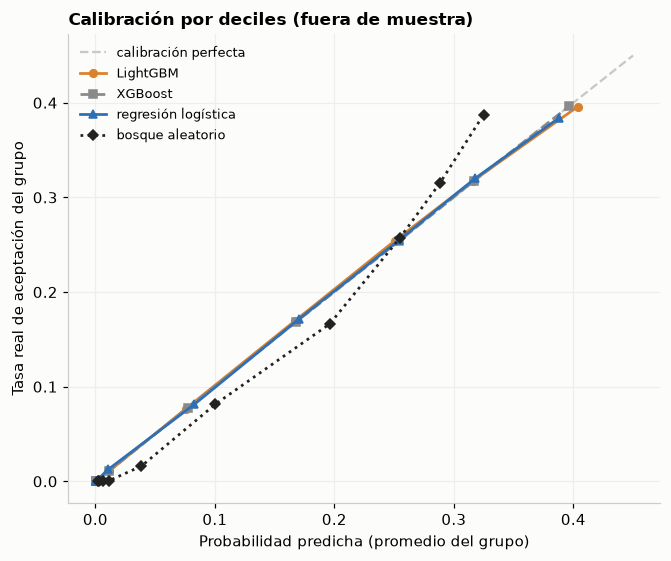

,mayor diferencia entre predicha y real en un grupo
LightGBM,0.0078
XGBoost,0.0007
regresión logística,0.0039
bosque aleatorio,0.0626


In [7]:
models_to_plot = {"LightGBM": ORANGE, "XGBoost": GRAY, "regresión logística": BLUE, "bosque aleatorio": INK}
fig, ax = plt.subplots(figsize=(6.2, 5.2))
ax.plot([0, 0.45], [0, 0.45], color=LIGHT, lw=1.5, ls="--", label="calibración perfecta")
styles = {"LightGBM": ("-", "o"), "XGBoost": ("--", "s"), "regresión logística": ("-", "^"), "bosque aleatorio": (":", "D")}
for name, color in models_to_plot.items():
    t = calibration_table(y, oof[name])
    ax.plot(t["predicted"], t["real"], color=color, ls=styles[name][0], marker=styles[name][1], ms=5, lw=1.8, label=name)
ax.set_xlabel("Probabilidad predicha (promedio del grupo)")
ax.set_ylabel("Tasa real de aceptación del grupo")
ax.set_title("Calibración por deciles (fuera de muestra)")
ax.legend(frameon=False, fontsize=8.5)
plt.tight_layout()
plt.show()

gap = pd.Series({n: (calibration_table(y, oof[n])["predicted"] - calibration_table(y, oof[n])["real"]).abs().max() for n in models_to_plot},
                name="mayor diferencia entre predicha y real en un grupo")
display(gap.round(4).to_frame())

**Lectura:** **XGBoost (diferencia máxima de 0,0007), la regresión (0,004) y LightGBM (0,008) están bien calibrados**: se puede usar la probabilidad tal cual. **El bosque aleatorio no** (0,063): en el grupo de mayor probabilidad **dice 32,5 % y en realidad compra el 38,8 %**, es decir, **subestima justo a los mejores clientes**. Por eso, con el umbral de 16,7 %, decide peor que la regresión aunque ordene igual.
**Consecuencia práctica:** si algún día se elige el bosque, habría que **calibrarlo** antes de usar un umbral. Es una de las cosas que la etapa 6 puede cambiar.

## 6. Comparación pareada de los mejores

Como todos se evaluaron en **los mismos pliegues**, se compara pliegue a pliegue. Una ventaja que gana en los 5 pliegues y supera varias veces su ruido es **consistente**; una que gana en 3 o 4 con ruido parecido a la diferencia es un **empate práctico**.

In [8]:
def paired(better, other, column, lower_is_better=True):
    # La lógica está en src/proyecto/models/metrics.py; aquí solo se le ponen nombres en español
    r = paired_comparison(per_fold, better, other, column, lower_is_better)
    return {"diferencia media": r["mean_difference"], "pliegues que gana": f"{r['folds_won']} de {r['n_folds']}",
            "diferencia / ruido": r["difference_over_noise"]}

pairs = [("LightGBM", "XGBoost"), ("LightGBM", "regresión logística"), ("XGBoost", "regresión logística"),
         ("LightGBM", "bosque aleatorio"), ("regresión logística", "bosque aleatorio"), ("regresión logística", "árbol de decisión")]
rows = []
for a, b in pairs:
    rows.append({"mejor": a, "contra": b, "métrica": "costo", **paired(a, b, "cost")})
    rows.append({"mejor": a, "contra": b, "métrica": "PR-AUC", **paired(a, b, "pr_auc", lower_is_better=False)})
display(pd.DataFrame(rows).set_index(["mejor", "contra", "métrica"]).style.format({"diferencia media": "{:+.4f}", "diferencia / ruido": "{:+.2f}"}))

**Lectura:**
- **LightGBM contra XGBoost: empate práctico.** En costo gana en 4 de 5 pliegues pero la diferencia es **+0,99** veces el ruido (justo en el umbral); en PR-AUC gana en 3 de 5 (+0,71). **No hay ventaja demostrable**: se desempata por **tiempo de ajuste** (≈ 3 s frente a ≈ 5 s) y simplicidad.
- **LightGBM contra la regresión: ventaja consistente.** Gana en **5 de 5** pliegues en costo (+1,87 veces el ruido) y en PR-AUC (**+10,1**). En ranking la diferencia es muy clara; en costo es real pero pequeña (≈ 0,0034).
- **Regresión contra bosque y contra árbol:** la regresión gana en **5 de 5** pliegues en costo (+4,5 y +3,3). **Un modelo simple le gana a un bosque de 150 árboles** cuando se mide el costo.
- **La regresión pierde contra el bosque en PR-AUC en los 5 pliegues** (-0,0057), pero **le gana en costo en los 5**: vuelve al efecto de la calibración de la sección 5.2.

## 7. ¿La elección cambia si cambia R?

**R = 5 es una hipótesis** (el costo de no llamar a un comprador frente a una llamada inútil). Se recalcula el costo de cada modelo para otros valores de R, **usando el umbral que corresponde a cada R** (1 ÷ (R + 1)) sobre las probabilidades fuera de muestra.

In [9]:
R_VALUES = [2, 3, 5, 8, 12]
sens = cost_sensitivity(y, oof, R_VALUES)            # la lógica está en src/proyecto/models/metrics.py
sens.loc["mejor modelo"] = [sens.drop(index="mejor modelo", errors="ignore")[c].idxmin() for c in sens.columns]
display(sens.style.format(lambda v: v if isinstance(v, str) else f"{v:.4f}"))

rule_probability = oof["línea base: llamar si hubo daño"].max()      # probabilidad que la regla asigna a un cliente con daño
rule_never_calls = [R for R in R_VALUES if 1 / (R + 1) > rule_probability]
print(f"La regla asigna {rule_probability:.1%} a quien tuvo daño. Con R en {rule_never_calls} el umbral la supera y la regla deja de llamar a todos.")

,R = 2,R = 3,R = 5,R = 8,R = 12
línea base: no llamar a nadie,0.2451,0.3677,0.6128,0.8774,0.8774
línea base: llamar si hubo daño,0.2451,0.3677,0.3980,0.4058,0.4163
regresión logística,0.2296,0.2813,0.3278,0.3620,0.3828
árbol de decisión,0.2451,0.2901,0.3377,0.3702,0.3832
bosque aleatorio,0.2374,0.2803,0.3355,0.3621,0.3911
LightGBM,0.2261,0.2783,0.3245,0.3574,0.3796
XGBoost,0.2260,0.2782,0.3259,0.3585,0.3795
mejor modelo,XGBoost,XGBoost,LightGBM,LightGBM,XGBoost


La regla asigna 23.8% a quien tuvo daño. Con R en [2, 3] el umbral la supera y la regla deja de llamar a todos.


**Lectura:**
- **LightGBM y XGBoost son siempre los dos mejores, en todos los valores de R** (se alternan el primer puesto con diferencias de milésimas): **la elección no depende de R**.
- **La regresión logística queda a unas 0,003 a 0,005 de los dos**: la distancia es estable.
- **El árbol pierde en todos los R**; **el bosque queda por detrás de la regresión salvo con R = 3**.
- **La regla simple deja de llamar (su costo coincide con el de "no llamar a nadie") cuando R es 3 o menos**, porque el umbral (25 % con R = 3) supera su probabilidad (≈ 23,8 %). Con R chico, **llamar casi no conviene** y el modelo gana poco en términos absolutos; con R grande, el modelo gana más.
- **Qué significa para el negocio:** confirmar R **mueve el costo absoluto y el umbral, pero no los finalistas**. Se puede avanzar a la etapa 6 sin esperar esa cifra.

## 8. ¿Cuánto vale la diferencia?

Se traduce el costo a **unidades de llamada por campaña** (`costo por cliente × clientes por campaña`). Para pasar a dinero basta multiplicar por el costo de una llamada **[PENDIENTE: dato externo · P01]**.

In [10]:
units = summary["unidades por campaña"]
rule_units = units["línea base: llamar si hubo daño"]
none_units = units["línea base: no llamar a nadie"]
value = pd.DataFrame({
    "unidades por campaña": units,
    "ahorro frente a la regla simple": rule_units - units,
    "ahorro frente a no llamar a nadie": none_units - units,
    "reducción frente a la regla simple": (rule_units - units) / rule_units,
})
display(value.style.format({"unidades por campaña": "{:,.0f}", "ahorro frente a la regla simple": "{:+,.0f}",
                            "ahorro frente a no llamar a nadie": "{:+,.0f}", "reducción frente a la regla simple": "{:+.1%}"}))

gap_lr = units["regresión logística"] - units["LightGBM"]
gap_xgb = units["XGBoost"] - units["LightGBM"]
noise_units = per_fold["LightGBM"]["cost"].std(ddof=1) * CLIENTES_POR_CAMPANA
print(f"LightGBM frente a la regresión: {gap_lr:,.0f} unidades por {CLIENTES_POR_CAMPANA:,} clientes. Frente a XGBoost: {gap_xgb:,.0f}. Ruido del costo: ≈ {noise_units:,.0f}.")

,unidades por campaña,ahorro frente a la regla simple,ahorro frente a no llamar a nadie,reducción frente a la regla simple
LightGBM,"32,446","+7,357","+28,836",+18.5%
XGBoost,"32,586","+7,218","+28,696",+18.1%
regresión logística,"32,782","+7,021","+28,500",+17.6%
bosque aleatorio,"33,548","+6,255","+27,733",+15.7%
árbol de decisión,"33,767","+6,036","+27,514",+15.2%
línea base: llamar si hubo daño,"39,803",+0,"+21,478",+0.0%
línea base: no llamar a nadie,"61,282","-21,478",+0,-54.0%


LightGBM frente a la regresión: 336 unidades por 100,000 clientes. Frente a XGBoost: 139. Ruido del costo: ≈ 358.


**Lectura de negocio:**
- **El valor está en pasar de la regla al modelo**, no en elegir entre modelos: el mejor ahorra **≈ 7.400 unidades por campaña de 100.000 clientes** frente a "llamar si hubo daño". Entre los tres primeros la diferencia es de **140 a 340 unidades**: **del orden del ruido (≈ 360)**.
- **Pagar por explicabilidad cuesta ≈ 340 unidades por campaña.** Es decir, **elegir la regresión (interpretable) sobre LightGBM le cuesta al negocio ≈ 1 % del costo total**. Si la explicación individual vale más que eso (regulación, confianza del equipo comercial, reclamos de clientes), la regresión es una elección razonable. **[PENDIENTE: dato externo · P03]** Mientras no se confirme, se **adopta por defecto** LightGBM como principal y la regresión como alternativa lista **[ADOPTADO · D10]**.
- **Un modelo que se opera con un presupuesto de llamadas fijo (20 %)** tiene un costo de ≈ 0,385: la capacidad limitada **le cuesta ≈ 6.000 unidades por campaña** al negocio. **Propuesta:** discutir con ventas si la capacidad real es 20 %, 35 % (lo que contacta el umbral) u otra cifra.

## 9. Efectos que la métrica principal no ve

### 9.1 ¿A quién contacta y a quién deja de contactar? (vista previa de equidad)

El costo promedio puede esconder que el modelo **casi no contacta** a ciertos grupos. Se revisa con las predicciones fuera de muestra del modelo líder y el umbral de 16,7 %. **Es una vista previa:** la auditoría completa de equidad se hace con la prueba cerrada en la etapa 7.

Por género (el modelo NO usa el género como variable):


,clientes,tasa real,% llamados,recall (compradores llamados),precisión (llamados que compran),compradores no llamados
Gender,,,,,,
Female,"140,107",10.4%,29.4%,85.3%,30.3%,"2,144"
Male,"164,780",13.8%,40.2%,88.2%,30.3%,"2,688"


Por tramo de edad:


,clientes,tasa real,% llamados,recall (compradores llamados),precisión (llamados que compran),compradores no llamados
tramo de edad,,,,,,
20-25,"91,667",3.5%,5.8%,36.3%,22.0%,"2,061"
26-35,"57,712",11.4%,29.0%,90.9%,35.6%,596
36-45,"56,414",21.5%,63.9%,97.3%,32.7%,323
46-55,"49,250",19.8%,63.7%,97.2%,30.2%,268
56-65,"27,375",14.0%,51.3%,88.0%,24.0%,460
66+,"22,469",8.4%,16.7%,40.2%,20.2%,"1,124"


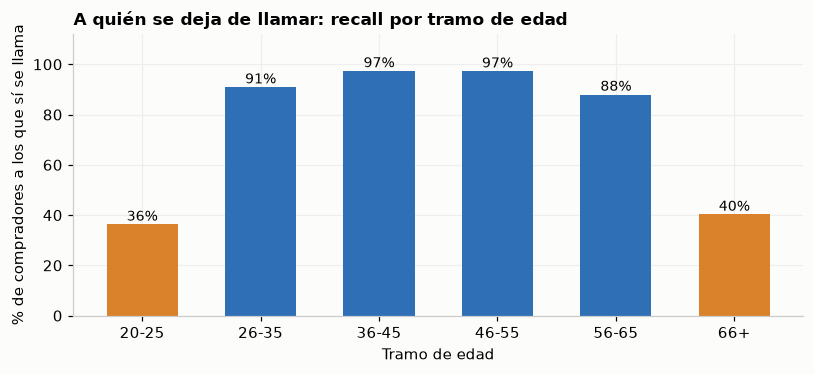

In [11]:
lead = "LightGBM"
audit = train[["Gender", "Age"]].copy()
audit["real"] = y.to_numpy()
audit["llamado"] = (oof[lead] >= decision_threshold()).astype(int)
audit["tramo de edad"] = pd.cut(audit["Age"], [19, 25, 35, 45, 55, 65, 90], labels=["20-25", "26-35", "36-45", "46-55", "56-65", "66+"])

AUDIT_LABELS = {"clients": "clientes", "real_rate": "tasa real", "called_rate": "% llamados", "recall": "recall (compradores llamados)",
                "precision": "precisión (llamados que compran)", "buyers_missed": "compradores no llamados"}

def audit_by(column):
    # La lógica está en src/proyecto/models/metrics.py; aquí solo se le ponen nombres en español
    return audit_by_group(y, oof[lead], audit[column]).rename(columns=AUDIT_LABELS)

fmt_audit = {"clientes": "{:,.0f}", "tasa real": "{:.1%}", "% llamados": "{:.1%}", "recall (compradores llamados)": "{:.1%}",
             "precisión (llamados que compran)": "{:.1%}", "compradores no llamados": "{:,.0f}"}
print("Por género (el modelo NO usa el género como variable):")
display(audit_by("Gender").style.format(fmt_audit))
print("Por tramo de edad:")
by_age = audit_by("tramo de edad")
display(by_age.style.format(fmt_audit))

fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.bar(range(len(by_age)), by_age["recall (compradores llamados)"] * 100, color=[ORANGE if v < 0.6 else BLUE for v in by_age["recall (compradores llamados)"]], width=0.6)
for i, v in enumerate(by_age["recall (compradores llamados)"]):
    ax.text(i, v * 100 + 1.5, f"{v:.0%}", ha="center", fontsize=9)
ax.set_xticks(range(len(by_age)))
ax.set_xticklabels(by_age.index)
ax.set_ylim(0, 112)
ax.set_xlabel("Tramo de edad")
ax.set_ylabel("% de compradores a los que sí se llama")
ax.set_title("A quién se deja de llamar: recall por tramo de edad")
plt.tight_layout()
plt.show()

**Lectura (vista previa para la etapa 7):**
- **Género:** el modelo no usa `Gender`, pero llama más a los hombres (**40,2 %**) que a las mujeres (**29,4 %**). **No es arbitrario:** los hombres compran más (13,8 % frente a 10,4 %) y **la precisión es idéntica (30,3 % en ambos)**, es decir, **una llamada rinde igual en los dos grupos**. La diferencia en recall es de **2,9 puntos** (88,2 % frente a 85,3 %).
- **Edad: aquí está el riesgo.** A los de **20 a 25 años** el modelo solo los llama el **5,8 %** y encuentra únicamente el **36 %** de sus compradores; a los de **66 o más**, el **16,7 %** y el **40 %**. En los tramos de 26 a 55 años el recall es de **91 % a 97 %**.
- **Por qué pasa y qué significa:** estos grupos compran poco (3,5 % y 8,4 %) y llamarlos **no compensa** con R = 5. Pero el costo agregado **esconde que una parte importante de los compradores jóvenes no recibe la oferta**: en el entrenamiento, **2.061 compradores de 20-25 años** (64 % de los suyos) y **1.124 de 66 o más** (60 %) **no son llamados**. Si la empresa quiere crecer en ese segmento, **no es un problema del modelo sino de política comercial**: hace falta otra oferta o canal para ellos, no más llamadas.
- **Propuesta [PENDIENTE: dato externo · P04, con Legal]:** (1) **documentar** que el modelo prioriza por rentabilidad esperada, no por perfil; (2) **definir si hay un piso de contacto** por tramo de edad; (3) repetir esta tabla con la prueba cerrada en la etapa 7.

### 9.2 Costo operativo de cada modelo

| | Ajuste (5 pliegues, ≈ 305.000 clientes) | Predicción de 61.000 clientes | Explicación individual |
|---|---|---|---|
| **LightGBM** | ≈ 3 s | ≈ 0,6 s | Poco directa (importancias y valores SHAP en la etapa 7) |
| **XGBoost** | ≈ 5 s | ≈ 0,3 s | Igual |
| **Regresión logística** | ≈ 2 s | ≈ 0,1 s | **Directa:** cada variable tiene un peso |
| **Bosque aleatorio** | ≈ 26 s | ≈ 0,5 s | Poco directa |

**Lectura:** ninguno es lento en términos de negocio (todos reentrenan en menos de un minuto). **El tiempo no es un criterio que decida aquí**, salvo para el bosque. Lo que sí decide es el costo, la consistencia y la explicabilidad.

In [12]:
timing = pd.DataFrame({n: {"segundos de ajuste": f["fit_seconds"].mean(), "segundos de predicción (61.000 clientes)": f["predict_seconds"].mean()} for n, f in per_fold.items()}).T.loc[summary.index]
display(timing.round(2))

# Se guarda la tabla del torneo para el informe y para poder reproducirla
export = summary.join(tech).join(ranks.add_prefix("posición: ")).round(5)
(ROOT / "reports").mkdir(exist_ok=True)
export.to_csv(ROOT / "reports" / "05_torneo_tabla.csv", index_label="modelo")
print("Guardado en reports/05_torneo_tabla.csv:", len(export), "modelos.")

,segundos de ajuste,segundos de predicción (61.000 clientes)
LightGBM,2.64,0.52
XGBoost,5.21,0.35
regresión logística,1.85,0.09
bosque aleatorio,24.41,0.47
árbol de decisión,0.80,0.05
línea base: llamar si hubo daño,0.03,0.03
línea base: no llamar a nadie,0.04,0.01


Guardado en reports/05_torneo_tabla.csv: 7 modelos.


## 10. Finalistas

Aplicando los criterios de la sección 1, en orden:

| Finalista | Por qué (consistencia, métrica, tiempo, explicabilidad) | Qué podría cambiar con la optimización (etapa 6) |
|---|---|---|
| **1. LightGBM** | **Menor costo (0,3245 ± 0,0036)**, gana en **5 de 5** pliegues a la regresión y al bosque; empata con XGBoost y se desempata por **tiempo** (≈ 3 s frente a ≈ 5 s). Probabilidades bien calibradas (diferencia máxima 0,008). Buen ranking: PR-AUC 0,371 | Ajustar número de árboles, tasa de aprendizaje y hojas; regularización; **elegir el umbral** con la capacidad real de llamadas; revisar **si XGBoost se acerca** tras ajustar a ambos |
| **2. Regresión logística (con edad como curva)** | **Costo 0,3278**, solo ≈ 340 unidades por campaña más que LightGBM (del orden del ruido), **supera a bosque, árbol y líneas base en los 5 pliegues**, calibrada y la **única que se explica con una fórmula**. Es el **finalista interpretable** | Probar **más curvas e interacciones** (por ejemplo edad × antigüedad del vehículo, o el perfil de 12 combinaciones que quedó en observación); regularización; verificar si **cierra la brecha** con los árboles |

**Modelos descartados y por qué:**
- **XGBoost:** **empate práctico con LightGBM** (+0,99 veces el ruido) y **casi el doble de lento**. No aporta nada que LightGBM no dé. **Queda como respaldo** si LightGBM da problemas al desplegar.
- **Bosque aleatorio:** **peor costo que la regresión** (5 de 5 pliegues perdidos), **9 veces más lento** y con **probabilidades mal calibradas** (subestima a los mejores clientes). Calibrarlo exigiría un paso más sin garantía de ganar.
- **Árbol de decisión:** **PR-AUC 0,31** frente a 0,36 de la regresión: lo simple de leer se paga con **peor ordenamiento** (la regresión le gana en los 5 pliegues). Si se necesitan **reglas legibles**, sirve para **explicar** cómo piensa el modelo, no para decidir.
- **Líneas base:** cumplieron su papel; **ningún modelo real las pierde**.

**Por qué el torneo no elige un campeón:** con parámetros de partida, la ventaja de LightGBM sobre XGBoost no pasa el umbral de +1 y la de la regresión es del orden del ruido; **la optimización puede mover el orden**. Y **ninguna de estas cifras viene de la prueba cerrada**: son validación cruzada. Solo la etapa 7 dirá qué tan bueno es el modelo que se elija.

### 10.1 Decisiones del negocio antes de la etapa 6: estado al cierre de la etapa 6

**Estado:** (1) explicación individual → **[PENDIENTE: dato externo · P03]**; por defecto LightGBM principal y regresión como alternativa **[ADOPTADO · D10]**. (2) capacidad → operar por umbral **[DECIDIDO · D08]**; la capacidad real sigue **[PENDIENTE: dato externo · P02]**. (3) valor de R → **[PENDIENTE: dato externo · P01]** (no bloquea). (4) piso de contacto → **[PENDIENTE: dato externo · P04]**. (5) criterio de reemplazo → **[ADOPTADO · D11]**.

| # | Decisión | Propuesta | Por qué importa |
|---|---|---|---|
| 1 | **¿Se exige explicar cada llamada?** | Sí para el modelo que se despliegue frente a clientes o reguladores; entonces la **regresión** pasa a primera línea | Cambia el finalista principal; cuesta ≈ 1 % del costo total |
| 2 | **Capacidad real de llamadas** | Confirmar con ventas: ¿20 %, 35 % u otra? | Define si se opera por **umbral** (probabilidad) o por **capacidad fija** (top N %) |
| 3 | **Valor de R** | Estimar margen por venta ÷ costo de llamada | No cambia los finalistas (sección 7), pero fija el **umbral** y el ahorro absoluto |
| 4 | **Política para clientes de 20-25 y 66+** | Definir si hay un **piso de contacto** o una oferta distinta | El modelo casi no los llama; es una decisión comercial, no técnica |
| 5 | **Criterio de reemplazo** | Reentrenar cuando la tasa real de aceptación se aleje de la predicha en más de un 10 % relativo durante 2 campañas | Mantiene el modelo útil en el tiempo |

## 11. Pruebas automáticas

In [13]:
import subprocess

res = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "--color=no", "tests/test_tournament.py", "tests/test_models.py"],
                     cwd=ROOT, capture_output=True, text=True)
print(res.stdout.strip().splitlines()[-1])
assert res.returncode == 0, res.stdout[-2000:]

25 passed in 8.16s


## Entregable de esta etapa

- [x] **5 modelos y 2 líneas base**, evaluados en **los mismos 5 pliegues**.
- [x] Una fila **por pliegue** guardada para cada modelo (`per_fold`) y las probabilidades fuera de muestra (`oof`).
- [x] **Métricas técnicas** (ROC-AUC, PR-AUC, exactitud balanceada, precisión y recall por clase, F1 macro, log loss, Brier) y **comparación entre el ranking de negocio y el técnico** (sección 5.1).
- [x] **Comparación pareada** de los mejores (pliegues que gana y diferencia / ruido).
- [x] La diferencia traducida a **unidades de llamada por campaña** (sección 8).
- [x] **2 finalistas** justificados (sección 10) y reflejados en `reports/05_torneo.md`.
- [x] El código reutilizable está en `src/proyecto/models/` y el notebook solo lo llama.
- [ ] El grupo confirma los criterios de elección y las decisiones de la sección 10.1.
- [ ] Revisión del código con `material-del-curso/kit/checklist-revision-ia.md`.

**Siguiente:** `06_optimizacion.ipynb`: se ajustan los dos finalistas y se elige el umbral.